In [81]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
from src.models import normal_equation

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [82]:
# Generating the data
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

X = 2 * np.random.rand(100, 1)

y = 4 + 3 * X + np.random.randn(100, 1)

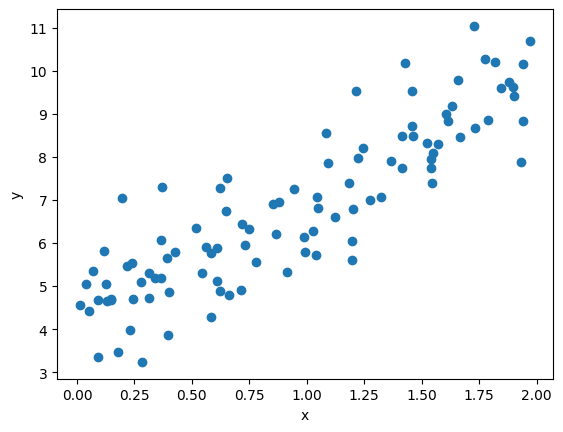

In [83]:
# Plot the raw data
plt.scatter(X, y)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [84]:
X_b = np.c_[np.ones((100, 1)), X]

The column of ones lets the model learn the bias/intercept as part of the parameter vector

In [85]:
theta_ = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y
print(theta_)

[[4.21509616]
 [2.77011339]]


In [86]:
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new]

y_predict = X_new_b @ theta_
print(y_predict)

[[4.21509616]
 [9.75532293]]


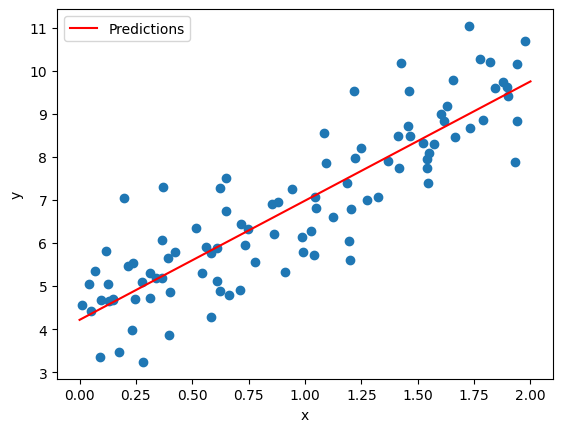

In [87]:
plt.scatter(X, y)
plt.plot(X_new, y_predict, c="red", label="Predictions")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [88]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [89]:
print("Normal Equation:")
print(theta_)

print("\nSklearn:")
print(lin_reg.intercept_)
print(lin_reg.coef_)


Normal Equation:
[[4.21509616]
 [2.77011339]]

Sklearn:
[4.21509616]
[[2.77011339]]


In [90]:
theta_pinv = np.linalg.pinv(X_b) @ y 

print("Normal Equation: ")
print(theta_)

print("\nPseudoinverse: ")
print(theta_pinv)

print(f"\n{np.allclose(theta_, theta_pinv)}")

Normal Equation: 
[[4.21509616]
 [2.77011339]]

Pseudoinverse: 
[[4.21509616]
 [2.77011339]]

True


why is pinv preferred over inv(XᵀX)?

np.linalg.pinv(X) is preferred because (X.T @ X)-1 may not exist when features are perfectly correlated or when there are more features than training instances. The pseudoinverse can still compute a least-square solution in these case and is generally more numerically robust

In [91]:
np.random.seed(42)

true_theta = np.array([[4], [3]])

for m in [10, 100, 1_000, 10_000]:
    errors = []

    for _ in range(200):
        X_m = 2 * np.random.rand(m, 1)
        y_m = 4 + 3 * X_m + np.random.randn(m, 1)

        errors.append(np.linalg.norm(normal_equation(X_m, y_m) - true_theta))
    
    print(f"m = {m:5d}, mean error = {np.mean(errors):.4f}")

m =    10, mean error = 0.7659
m =   100, mean error = 0.2266
m =  1000, mean error = 0.0644
m = 10000, mean error = 0.0206


In [92]:
# Migration Check: normal_equation

theta_src = normal_equation(X, y)
print(np.allclose(theta_, theta_src))

True


The Normal Equation requires inverting X^TX, whose computational cost is roughly O(n^3) with n features, while forming X^TX scales roughly with the number of instances m. Therefore, 100,000 features make the Normal Equation impractical because they require inverting a 100000 x 100000 matrix, whereas 100,000 rows with only a few features are much more manageable. This is one reason Gradient Descent is useful for high-dimensional problems.

In [93]:
# SVD decomposition
U, s, Vt = np.linalg.svd(X_b, full_matrices=False)

# Build Sigma+
Sigma_pinv = np.diag(1 / s)

# Build X_b+
X_b_pinv = Vt.T @ Sigma_pinv @ U.T

# Calculate theta using the manually-built pseudoinverse
theta_svd = X_b_pinv @ y

print("NumPy pinv:")
print(theta_pinv)

print("\nManual SVD:")
print(theta_svd)

print("\nSame result?")
print(np.allclose(theta_svd, theta_pinv))

NumPy pinv:
[[4.21509616]
 [2.77011339]]

Manual SVD:
[[4.21509616]
 [2.77011339]]

Same result?
True


Why does SVD make pinv robust?

The pseudoinverse works with the singular values of X_b. Very small singular values indicate directions where the matrix contains little or redundant information. Directly taking their reciprocal can produce extremely large values, making the solution numerically unstable. np.linalg.pinv() handles these near-zero singular values using a tolerance, effectively treating sufficiently small values as zero. This allows it to handle rank-deficient or highly correlated features much more safely than explicitly computing (X^TX)^-1.